# Broiler growth and feed efficiency with dietary cricket meal

## 1. Introduction

Cricket meal is one of the insect proteins being tested as a partial replacement for conventional protein sources in broiler diets. This notebook works through the open growth data of one such trial and asks one question:

**How did dietary cricket-meal inclusion influence broiler growth and feed efficiency?**

The emphasis is on handling experimental data carefully. The spreadsheet was laid out for people, not for software, so it has to be read and checked before anything is calculated. The production variables are then calculated from the measurements and summarised with the pen as the experimental unit. This is not an attempt to reproduce the published paper.

This is the first of three notebooks. The second (`02_organs_meat_quality.ipynb`) covers organ weights, gut lesions and breast meat. The third (`03_prediction_models.ipynb`) tries simple prediction models.

## 2. Data source and experimental design

The data come from the Mendeley Data record *"The effects of cricket meal (Gryllus sigillatus) on the meat quality, growth, and internal morphology of broiler chickens"* (version 1, 2022, [doi:10.17632/rj5fybnzh6.1](https://doi.org/10.17632/rj5fybnzh6.1), CC BY 4.0). The record says the work was done for the MSc thesis of Holly Fisher at Dalhousie University. The journal article is Fisher et al. (2024), *Canadian Journal of Animal Science* 104(3): 285-300, [doi:10.1139/cjas-2023-0105](https://doi.org/10.1139/cjas-2023-0105).

According to the dataset description:

- 624 Ross 308 broilers, 26 birds per pen
- six diets: 0% cricket meal non-medicated control (NM), 0% medicated control (M), and 5, 10, 15 and 20% cricket meal (CM), all non-medicated
- body weight and feed intake recorded weekly
- three birds per pen taken on days 13, 20 and 35 for organ measurements

The article abstract gives the medication in the medicated control as 0.05% virginiamycin and 0.03% monensin, and the trial length as 35 days.

That is what the source says. What the workbook actually contains is checked in sections 4 to 9, not assumed.

## 3. Imports and settings

In [1]:
import hashlib
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import scipy
from scipy import stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

DATA_FILE = Path("data") / "H Fisher Growth 22 - Open access.xlsx"
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

## 4. Loading the Excel workbook

The workbook is not stored in this repository (see `data/README.md`). On Colab the next cell asks for it once and saves it under `data/`. The file is only read. Nothing is ever written back to it.

In [2]:
if not DATA_FILE.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Download the workbook from Mendeley Data and save it as '{DATA_FILE}'") from None
    uploaded = files.upload()
    DATA_FILE.parent.mkdir(exist_ok=True)
    DATA_FILE.write_bytes(next(iter(uploaded.values())))

print("Workbook:", DATA_FILE.name)
print("SHA-256 :", hashlib.sha256(DATA_FILE.read_bytes()).hexdigest())

Workbook: H Fisher Growth 22 - Open access.xlsx
SHA-256 : 2c0e12849a7441e66ee190f0c438d84d914ceae9d51b9b97367f64ec5737a118


In [3]:
# header=None reads every cell where it sits in the spreadsheet, without guessing which row holds the column names
sheets_raw = pd.read_excel(DATA_FILE, sheet_name=None, header=None)

pd.DataFrame(
    [(name, sheet.shape[0], sheet.shape[1]) for name, sheet in sheets_raw.items()],
    columns=["sheet", "rows", "columns"],
)

,sheet,rows,columns
0,Growth data,157,37
1,Organ weights and indices,228,19
2,"Meat yield, breast & liver Lab",84,28
3,Meat cook yield,84,9
4,Meat texture,301,7
5,Intestinal lesion scores,157,42


Six sheets. Only `Growth data` holds body weight and feed intake. The other five (organ weights, meat yield, cooking loss, texture, lesion scores) are analysed in the second notebook. The organ sheet is used once here, in section 5, to confirm when birds left the pens.

## 5. Initial data audit

I look at the sheet as it is before changing anything, so that real missing observations can be told apart from blanks that come from the spreadsheet layout.

In [4]:
raw = sheets_raw["Growth data"]
print("Shape as read:", raw.shape)
raw.iloc[:16, :11]

Shape as read: (157, 37)


,0,1,2,3,4,5,6,7,8,9,10
0,Key,Key,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Treatment,Diet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,0NM,Non-medicated control diet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2,0M,Medicated control diet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3,5,5% dietary inclusion of oven-dried cricket meal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4,10,10% dietary inclusion of oven-dried cricket meal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,5,15,15% dietary inclusion of oven-dried cricket meal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,6,20,20% dietary inclusion of oven-dried cricket meal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,Growth and feed intake data for broilers fed e...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Rows 0 to 7 are a key to the treatment codes, row 9 is a title, row 11 names a table and the column labels only come in row 12. Rows and columns are counted from zero here, as in the table above. Row 12 is row 13 in the spreadsheet, and column 0 is column A.

The sheet is 37 columns wide. Before deciding what is data I check for merged cells and formulas, and then look at what the label row holds across the full width.

In [5]:
sheet = openpyxl.load_workbook(DATA_FILE)["Growth data"]
print("Merged cell ranges     :", len(sheet.merged_cells.ranges))
print("Cells holding a formula:", sum(cell.data_type == "f" for row in sheet.iter_rows() for cell in row))

Merged cell ranges     : 0


Cells holding a formula: 0


No merged cells and no formulas. The gain and feed:gain columns are stored as plain numbers, so the file does not show how they were calculated. That is one reason to calculate them again in section 9.

In [6]:
header_row = raw.index[raw[0] == "Pen"][0]
print("Column labels are in row", header_row)

pd.DataFrame({
    "table title (row above)": raw.loc[header_row - 1],
    "column label": raw.loc[header_row],
}).dropna(how="all").fillna("")

Column labels are in row 12


,table title (row above),column label
0,,Pen
1,Sorted by week,Treatment
2,,Diet
3,,Day
4,,Period
5,,Rep
6,,Average weight (g)
7,,Daily feed intake (g)
8,,Daily weight gain (g/d)
9,,Feed : Gain


The label row shows three tables side by side, separated by empty columns. The weekly records are in columns 0 to 10. The same pens summarised by feeding period are in columns 14 to 23. The 35-day totals are in columns 27 to 36, with one unlabelled empty column inside. I cut the tables apart at these positions.

In [7]:
first_data_row = header_row + 1


def cut_table(first_col, last_col):
    """Cut one of the side-by-side tables out of the sheet, keeping its original column labels."""
    table = raw.iloc[first_data_row:, first_col:last_col + 1].copy()
    table.columns = raw.iloc[header_row, first_col:last_col + 1].tolist()
    return table


weekly_raw = cut_table(0, 10)
period_raw = cut_table(14, 23)
total_raw = cut_table(27, 36)

for name, table in [("weekly", weekly_raw), ("period", period_raw), ("total", total_raw)]:
    rows_with_data = table.notna().any(axis=1).sum()
    print(f"{name:7s} rows with data: {rows_with_data:3d}   completely empty rows: {len(table) - rows_with_data:3d}")

weekly  rows with data: 144   completely empty rows:   0
period  rows with data:  96   completely empty rows:  48
total   rows with data:  24   completely empty rows: 120


The weekly table fills all 144 rows. The period and total tables are shorter, so the empty rows below them are layout, not missing data. Section 8 confirms that both are calculated from the weekly table. The weekly table is therefore the data, and the other two are kept only to check calculations.

Now the weekly table itself: labels, first rows, what kind of value each column holds, missing values, duplicates and the labels used.

In [8]:
print(list(weekly_raw.columns))
weekly_raw.head(8)

['Pen', 'Treatment ', 'Diet', 'Day ', 'Period ', 'Rep', 'Average weight (g) ', 'Daily feed intake (g)', ' Daily weight gain (g/d)', 'Feed : Gain ', '% Mortalities']


,Pen,Treatment,Diet,Day,Period,Rep,Average weight (g),Daily feed intake (g),Daily weight gain (g/d),Feed : Gain,% Mortalities
13,1,1,0NM,0,S,1,38.666667,.,.,.,.
14,2,2,0M,0,S,1,38.037037,.,.,.,.
15,3,2,0M,0,S,2,39.692308,.,.,.,.
16,3.749799,4,10,0,S,1,39.296296,.,.,.,.
17,4.741147,4,10,0,S,2,39.230769,.,.,.,.
18,5.694366,3,5,0,S,1,39.296296,.,.,.,.
19,6.723843,1,0NM,0,S,2,38.923077,.,.,.,.
20,7.791449,5,15,0,S,1,38.592593,.,.,.,.


In [9]:
def count_cells(column, kind):
    """Number of cells in a column that hold a value of the given type."""
    return column.map(lambda value: isinstance(value, kind)).sum()


# Count what each column holds cell by cell: a numeric column with a few text cells is easy to miss otherwise
pd.DataFrame({
    "whole numbers": weekly_raw.apply(count_cells, kind=int),
    "decimals": weekly_raw.apply(count_cells, kind=float),
    "text": weekly_raw.apply(count_cells, kind=str),
    "empty cells": weekly_raw.isna().sum(),
    "cells holding '.'": (weekly_raw == ".").sum(),
})

,whole numbers,decimals,text,empty cells,cells holding '.'
Pen,18,126,0,0,0
Treatment,144,0,0,0,0
Diet,96,0,48,0,0
Day,144,0,0,0,0
Period,0,0,144,0,0
Rep,144,0,0,0,0
Average weight (g),3,141,0,0,0
Daily feed intake (g),1,119,24,0,24
Daily weight gain (g/d),0,120,24,0,24
Feed : Gain,0,120,24,0,24


In [10]:
print("Duplicate rows:", weekly_raw.duplicated().sum())
print()
for col in weekly_raw.columns[:6]:
    print(f"{col!r:13s}", weekly_raw[col].unique().tolist())

Duplicate rows: 0

'Pen'         [1, 2, 3, 3.74979879275654, 4.74114688128773, 5.6943661971831, 6.7238430583501, 7.79144869215292, 8.76360137083811, 9.75425244197869, 10.7879752988211, 11.8647699413652, 12.8984927982075, 13.9322156550499, 15.009010297594, 15.9135177973311, 16.9903124398752, 17.8948199396122, 18.9716145821563, 19.8761220818934, 20.866773153034, 21.9435677955781, 22.8911470810169, 23.795654580754]
'Treatment '  [1, 2, 4, 3, 5, 6]
'Diet'        ['0NM', '0M', 10, 5, 15, 20]
'Day '        [0, 7, 14, 21, 28, 35]
'Period '     ['S', 'G', 'F']
'Rep'         [1, 2, 3, 4]


### The experiment as it appears in the file

Before cleaning, I want to know what the experimental unit is and how the rows relate to it. The pen column is clearly damaged (see above), so I count pens as combinations of treatment and replicate number, which are intact.

In [11]:
labels = weekly_raw.rename(columns=str.strip)
pens = labels.groupby(["Treatment", "Rep"]).size()

print("Experimental unit      : pen (one Treatment x Rep combination)")
print("Treatments             :", labels["Treatment"].nunique())
print("Pens                   :", len(pens))
print("Pens per treatment     :", sorted(pens.groupby(level="Treatment").size().unique().tolist()))
print("Weighing days          :", sorted(labels["Day"].unique().tolist()))
print("Weighings per pen      :", sorted(pens.unique().tolist()))
print("Rows = pens x weighings:", len(labels), "=", len(pens), "x", labels["Day"].nunique())
print("Birds per pen at start : 26 according to the dataset description (the sheet has no bird-count column)")

Experimental unit      : pen (one Treatment x Rep combination)
Treatments             : 6
Pens                   : 24
Pens per treatment     : [4]
Weighing days          : [0, 7, 14, 21, 28, 35]
Weighings per pen      : [6]
Rows = pens x weighings: 144 = 24 x 6
Birds per pen at start : 26 according to the dataset description (the sheet has no bird-count column)


Each pen appears six times. Those six rows are repeated measurements on the same experimental unit, not six independent observations. The sample size for comparing diets is 4 pens per diet (24 in total), not 144.

The sheet gives mean values per bird, and the number of birds behind a mean changed during the trial. The organ sheet shows when birds were taken out:

In [12]:
organ_raw = sheets_raw["Organ weights and indices"]
organ_header = organ_raw.index[organ_raw[0] == "Pen"][0]
print("First labels of the organ sheet:", organ_raw.iloc[organ_header, :4].tolist())

organ = organ_raw.iloc[organ_header + 1:, [0, 3]].dropna()
organ.columns = ["pen", "day"]

print("Birds per pen on each sampling day:", organ.groupby(["day", "pen"]).size().unique().tolist())
organ.groupby("day")["pen"].agg(pens="nunique", birds="size")

First labels of the organ sheet: ['Pen', 'Treatment', 'Bird ', 'Day ']
Birds per pen on each sampling day: [3]


,pens,birds
day,,
13,24,72
20,24,72
35,24,72


Three birds were taken from every pen on days 13, 20 and 35. So each pen was three birds smaller at the day-14 weighing and six birds smaller from day 21 on, before counting any mortality. This matters in section 9.

### What the audit found

- **Layout:** key and title rows above the data, column labels in row 12 (row 13 in the spreadsheet), three tables side by side with empty columns between them. No merged cells, no formulas.
- **Summary tables:** the period and total tables repeat the weekly data in summarised form.
- **Column labels:** several carry stray spaces (`'Treatment '`, `'Day '`, `' Daily weight gain (g/d)'`).
- **Missing values:** the weekly table has no empty cells, but 96 cells hold a full stop, 24 in each of the four columns that describe a week.
- **Mixed types:** the diet column mixes text (`0NM`, `0M`) with numbers (5, 10, 15, 20).
- **Pen identifiers:** only 18 of the 144 cells are whole numbers. The rest are decimals such as 3.7498.
- **Duplicate rows:** none.
- **Design:** 6 treatments x 4 pens = 24 pens, each weighed 6 times, as the description says. The sheet has no column for the number of birds. Section 9.1 looks at what the weights and the mortality column say about "26 birds per pen".

## 6. Data cleaning

Each step changes one thing, and only things the audit showed to be wrong. The tables cut from the sheet (`weekly_raw`, `period_raw`, `total_raw`) are left untouched, so every step can be compared with the original.

### 6.1 Column names

Labels are stripped of stray spaces and replaced by short names that carry the unit. Columns calculated by the authors are marked `supplied`, to keep them apart from the values calculated in this notebook.

In [13]:
new_names = {
    "Pen": "pen",
    "Treatment": "treatment",
    "Diet": "diet_code",
    "Day": "day",
    "Period": "phase_code",
    "Rep": "rep",
    "Average weight (g)": "body_weight_g",
    "Daily feed intake (g)": "feed_intake_g_d",
    "Daily weight gain (g/d)": "gain_supplied_g_d",
    "Feed : Gain": "feed_gain_supplied",
    "% Mortalities": "mortality_pct",
    "Total Weight gain (g)": "total_gain_supplied_g",
}


def tidy_names(table):
    """Drop empty rows and columns, strip stray spaces from the labels and apply the new names."""
    table = table.dropna(how="all").dropna(axis=1, how="all")
    table.columns = table.columns.str.strip()
    return table.rename(columns=new_names).reset_index(drop=True)


weekly = tidy_names(weekly_raw).rename(columns={"pen": "pen_as_entered"})
period = tidy_names(period_raw)
total = tidy_names(total_raw)

print("Weekly rows removed as completely empty:", len(weekly_raw) - len(weekly))
print(list(weekly.columns))

Weekly rows removed as completely empty: 0
['pen_as_entered', 'treatment', 'diet_code', 'day', 'phase_code', 'rep', 'body_weight_g', 'feed_intake_g_d', 'gain_supplied_g_d', 'feed_gain_supplied', 'mortality_pct']


### 6.2 Missing-value code and numeric columns

Before converting to numbers I check what the text entries actually are. The conversion turns every text entry into a missing value, so I want to be sure that the full stop is the only one.

In [14]:
measure_cols = ["body_weight_g", "feed_intake_g_d", "gain_supplied_g_d", "feed_gain_supplied", "mortality_pct"]

for col in measure_cols:
    text_cells = weekly.loc[weekly[col].map(lambda value: isinstance(value, str)), col]
    print(f"{col:20s} text cells: {len(text_cells):2d}   distinct entries: {sorted(text_cells.unique().tolist())}")

body_weight_g        text cells:  0   distinct entries: []
feed_intake_g_d      text cells: 24   distinct entries: ['.']
gain_supplied_g_d    text cells: 24   distinct entries: ['.']
feed_gain_supplied   text cells: 24   distinct entries: ['.']
mortality_pct        text cells: 24   distinct entries: ['.']


In [15]:
weekly[measure_cols] = weekly[measure_cols].apply(pd.to_numeric, errors="coerce")
weekly[["treatment", "day", "rep"]] = weekly[["treatment", "day", "rep"]].astype(int)

missing = weekly[measure_cols].isna()
print(missing.sum().to_string())
print()
print("Days on which values are missing:", sorted(weekly.loc[missing.any(axis=1), "day"].unique().tolist()))

body_weight_g          0
feed_intake_g_d       24
gain_supplied_g_d     24
feed_gain_supplied    24
mortality_pct         24

Days on which values are missing: [0]


The full stop is the only text entry, and the 96 missing values are all on day 0. Feed intake, gain, feed:gain and mortality describe the week that ended at a weighing, so they cannot exist for the day the chicks were placed. These gaps belong to the design. They are not lost observations, and no row has to be dropped.

The two summary tables get the same treatment. They are only used for checks.

In [16]:
period[measure_cols] = period[measure_cols].apply(pd.to_numeric, errors="coerce")
period[["pen", "treatment", "rep"]] = period[["pen", "treatment", "rep"]].astype(int)
period["phase"] = period["phase_code"].str.strip()

total_cols = ["feed_intake_g_d", "gain_supplied_g_d", "feed_gain_supplied", "total_gain_supplied_g"]
total[total_cols] = total[total_cols].apply(pd.to_numeric)
total[["pen", "treatment", "rep"]] = total[["pen", "treatment", "rep"]].astype(int)

### 6.3 Pen identifiers

The pen is the experimental unit, so its identifier has to be right. The decimals cannot be used as they are, but they are not random either.

In [17]:
whole_number = weekly["pen_as_entered"].map(lambda value: float(value).is_integer())
print("Pen cells holding a whole number:", whole_number.sum(), "of", len(weekly))

entered = weekly.pivot(index=["treatment", "rep"], columns="day", values="pen_as_entered")
print("Same entry at every weighing for a given treatment and rep:", (entered.nunique(axis=1) == 1).all())

Pen cells holding a whole number: 18 of 144
Same entry at every weighing for a given treatment and rep: True


The same 24 entries repeat at every weighing and rise in steps of about one. That looks like a spreadsheet fill that went wrong, not 24 measurements. A pen is also identified by its treatment and replicate number, and the total table lists the pen number for each treatment and rep as whole numbers. I take the pen numbers from there instead of guessing.

In [18]:
pen_key = total[["treatment", "rep", "pen"]]
matched = weekly[["treatment", "rep"]].merge(pen_key, on=["treatment", "rep"], how="left", validate="many_to_one")
weekly["pen"] = matched["pen"].to_numpy()

# Independent evidence: the period table has its own pen column and its own copy of the day-0 weights
period_pens = period.merge(pen_key, on=["treatment", "rep"], suffixes=("", "_from_total"))
day0_weekly = weekly[weekly["day"] == 0].set_index("pen")["body_weight_g"].sort_index()
day0_period = period[period["phase"] == "Day 0"].set_index("pen")["body_weight_g"].sort_index()

print("Pen found for every row:", weekly["pen"].notna().all())
print("Same as the entered value rounded to a whole number:",
      (weekly["pen"] == weekly["pen_as_entered"].astype(float).round()).all())
print("Period table gives the same pen for each treatment and rep:",
      (period_pens["pen"] == period_pens["pen_from_total"]).all())
print("Day-0 weights match the period table pen by pen:", np.allclose(day0_weekly, day0_period))

Pen found for every row: True
Same as the entered value rounded to a whole number: True
Period table gives the same pen for each treatment and rep: True
Day-0 weights match the period table pen by pen: True


The checks agree. In all 144 rows the pen number taken from treatment and rep equals the entered value rounded to the nearest whole number. The period table gives the same pen for each treatment and rep. The day-0 weights match the period table pen by pen.

### 6.4 Treatment labels and feeding phase

The key at the top of the sheet says what the codes mean.

In [19]:
key = raw.iloc[2:8, 0:3].copy()
key.columns = ["treatment code", "label in workbook", "description"]
key

,treatment code,label in workbook,description
2,1,0NM,Non-medicated control diet
3,2,0M,Medicated control diet
4,3,5,5% dietary inclusion of oven-dried cricket meal
5,4,10,10% dietary inclusion of oven-dried cricket meal
6,5,15,15% dietary inclusion of oven-dried cricket meal
7,6,20,20% dietary inclusion of oven-dried cricket meal


The workbook labels mix text and numbers, so I replace them with labels that show both the inclusion level and the type of control (NM = non-medicated control, M = medicated control, CM = cricket meal). These are the labels the authors use in the lesion-score sheet of the same workbook. They are stored as an ordered category so that tables and plots keep the dose order.

In [20]:
diet_names = {1: "0% NM", 2: "0% M", 3: "5% CM", 4: "10% CM", 5: "15% CM", 6: "20% CM"}
diet_order = list(diet_names.values())

weekly["diet"] = pd.Categorical(weekly["treatment"].map(diet_names), categories=diet_order, ordered=True)

# Each new label should line up with exactly one original label
pd.crosstab(weekly["diet"], weekly["diet_code"].astype(str))

diet_code,0M,0NM,10,15,20,5
diet,,,,,,
0% NM,0,24,0,0,0,0
0% M,24,0,0,0,0,0
5% CM,0,0,0,0,0,24
10% CM,0,0,24,0,0,0
15% CM,0,0,0,24,0,0
20% CM,0,0,0,0,24,0


In [21]:
weekly["phase"] = pd.Categorical(
    weekly["phase_code"].map({"S": "Starter", "G": "Grower", "F": "Finisher"}),
    categories=["Starter", "Grower", "Finisher"], ordered=True,
)
pd.crosstab(weekly["phase"], weekly["day"])

day,0,7,14,21,28,35
phase,,,,,,
Starter,24,24,24,24,0,0
Grower,0,0,0,0,24,0
Finisher,0,0,0,0,0,24


The weighings up to day 21 are coded starter, day 28 closes the grower week and day 35 the finisher week.

### 6.5 Analysis-ready table and cleaning log

In [22]:
growth_long = (
    weekly[["pen", "treatment", "diet", "rep", "day", "phase",
            "body_weight_g", "feed_intake_g_d", "gain_supplied_g_d", "feed_gain_supplied", "mortality_pct"]]
    .sort_values(["treatment", "pen", "day"])
    .reset_index(drop=True)
)

print(growth_long.dtypes.to_string())
growth_long.head(12)

pen                      int64
treatment                int64
diet                  category
rep                      int64
day                      int64
phase                 category
body_weight_g          float64
feed_intake_g_d        float64
gain_supplied_g_d      float64
feed_gain_supplied     float64
mortality_pct          float64


,pen,treatment,diet,rep,day,phase,body_weight_g,feed_intake_g_d,gain_supplied_g_d,feed_gain_supplied,mortality_pct
0,1,1,0% NM,1,0,Starter,38.666667,NaN,NaN,NaN,NaN
1,1,1,0% NM,1,7,Starter,138.375000,21.088360,14.244048,1.480503,11.111111
2,1,1,0% NM,1,14,Starter,366.619048,39.127551,32.606293,1.200000,0.000000
3,1,1,0% NM,1,21,Starter,781.722222,91.281293,48.132993,1.896439,4.761905
4,1,1,0% NM,1,28,Grower,1336.611111,139.682540,90.437302,1.544524,0.000000
5,1,1,0% NM,1,35,Finisher,2067.277778,137.388889,104.380952,1.316226,0.000000
6,7,1,0% NM,2,0,Starter,38.923077,NaN,NaN,NaN,NaN
7,7,1,0% NM,2,7,Starter,135.576923,24.373626,13.807692,1.765221,0.000000
8,7,1,0% NM,2,14,Starter,347.826087,48.294075,30.321309,1.592744,0.000000
9,7,1,0% NM,2,21,Starter,788.550000,125.153106,62.960559,1.987802,0.000000


In [23]:
cleaning_log = pd.Series({
    "Rows in the sheet as read": len(raw),
    "Rows above the data (key, titles, column labels)": first_data_row,
    "Rows in the weekly table": len(weekly_raw),
    "Rows removed as completely empty": len(weekly_raw) - len(weekly),
    "Duplicate rows": int(weekly_raw.duplicated().sum()),
    "Duplicate pen-day records": int(growth_long.duplicated(["pen", "day"]).sum()),
    "Cells holding '.' set to missing (all on day 0)": int(missing.sum().sum()),
    "Missing values after day 0": int(missing[weekly["day"] > 0].sum().sum()),
    "Pen identifiers restored": int((~whole_number).sum()),
    "Rows removed for any other reason": len(weekly) - len(growth_long),
    "Final usable rows": len(growth_long),
})
print(cleaning_log.to_string())

Rows in the sheet as read                           157
Rows above the data (key, titles, column labels)     13
Rows in the weekly table                            144
Rows removed as completely empty                      0
Duplicate rows                                        0
Duplicate pen-day records                             0
Cells holding '.' set to missing (all on day 0)      96
Missing values after day 0                            0
Pen identifiers restored                            126
Rows removed for any other reason                     0
Final usable rows                                   144


Nothing was deleted. The cleaning consisted of cutting the weekly table out of the sheet, renaming columns, recoding the missing-value mark, restoring the pen numbers and relabelling the diets.

## 7. Reshaping and variable preparation

The weekly table already has the shape that analysis needs, often called long or tidy format: one row per pen per weighing, one column per variable. It does not have to be rearranged. Two things still need attention.

First, the columns do not all describe the same thing. Body weight is a measurement at one moment. Feed intake, gain and mortality describe the seven days before that weighing. A `week` column makes this explicit: week 1 is days 0 to 7, and week 0 is placement, which has a weight but no intake.

Second, comparing diets needs one row per pen, with the weighings side by side as columns (wide format).

In [24]:
growth_long["week"] = growth_long["day"] // 7

bw_wide = growth_long.pivot(index="pen", columns="day", values="body_weight_g")

weekly_records = growth_long[growth_long["week"] > 0]
intake_wide = weekly_records.pivot(index="pen", columns="week", values="feed_intake_g_d")
gain_wide = weekly_records.pivot(index="pen", columns="week", values="gain_supplied_g_d")

bw_wide.round(2).head()

day,0,7,14,21,28,35
pen,,,,,,
1,38.67,138.38,366.62,781.72,1336.61,2067.28
2,38.04,124.15,329.79,729.76,1306.90,2002.38
3,39.69,128.77,352.96,748.60,1347.65,2044.55
4,39.30,152.58,399.96,704.26,1406.45,2098.25
5,39.23,143.12,380.09,702.91,1414.50,2088.80


## 8. Quality-control checks

### 8.1 Does the table match the design?

In [25]:
records_per_pen = growth_long.groupby("pen").size()
treatments_per_pen = growth_long.groupby("pen")["treatment"].nunique()
pens_per_diet = growth_long.groupby("diet", observed=True)["pen"].nunique()

print("Pens:", growth_long["pen"].nunique())
print("Every pen has 6 weighings:", (records_per_pen == 6).all())
print("Every pen belongs to one treatment only:", (treatments_per_pen == 1).all())
print("Pens per diet:", pens_per_diet.to_dict())

Pens: 24
Every pen has 6 weighings: True
Every pen belongs to one treatment only: True
Pens per diet: {'0% NM': 4, '0% M': 4, '5% CM': 4, '10% CM': 4, '15% CM': 4, '20% CM': 4}


### 8.2 Are the period and total tables extra data?

If they were separate measurements they would have to be analysed. If they are calculated from the weekly table they add nothing, but they show how the authors calculated their totals.

In [26]:
total_by_pen = total.set_index("pen").sort_index()
period_by_pen = period.set_index(["phase", "pen"]).sort_index()


def pens_agreeing(a, b):
    """Number of pens for which two pen-indexed series hold the same value."""
    return int(np.isclose(a.sort_index(), b.sort_index()).sum())


checks = {
    "Starter weight = day-21 weight": (period_by_pen.loc["Starter", "body_weight_g"], bw_wide[21]),
    "Starter feed intake = mean of weeks 1 to 3": (period_by_pen.loc["Starter", "feed_intake_g_d"], intake_wide[[1, 2, 3]].mean(axis=1)),
    "Starter daily gain = mean of weeks 1 to 3": (period_by_pen.loc["Starter", "gain_supplied_g_d"], gain_wide[[1, 2, 3]].mean(axis=1)),
    "Grower feed intake = week 4": (period_by_pen.loc["Grower", "feed_intake_g_d"], intake_wide[4]),
    "Grower daily gain = week 4": (period_by_pen.loc["Grower", "gain_supplied_g_d"], gain_wide[4]),
    "Finisher feed intake = week 5": (period_by_pen.loc["Finisher", "feed_intake_g_d"], intake_wide[5]),
    "Finisher daily gain = week 5": (period_by_pen.loc["Finisher", "gain_supplied_g_d"], gain_wide[5]),
    "Total feed intake = mean of the five weeks": (total_by_pen["feed_intake_g_d"], intake_wide.mean(axis=1)),
    "Total daily gain = mean of the five weeks": (total_by_pen["gain_supplied_g_d"], gain_wide.mean(axis=1)),
    "Total weight gain = 35 x total daily gain": (total_by_pen["total_gain_supplied_g"], 35 * total_by_pen["gain_supplied_g_d"]),
    "Total feed:gain = total intake / total daily gain": (total_by_pen["feed_gain_supplied"], total_by_pen["feed_intake_g_d"] / total_by_pen["gain_supplied_g_d"]),
}
for label, (supplied, recalculated) in checks.items():
    print(f"{label:50s} {pens_agreeing(supplied, recalculated):2d} of 24 pens")

Starter weight = day-21 weight                     24 of 24 pens
Starter feed intake = mean of weeks 1 to 3         24 of 24 pens
Starter daily gain = mean of weeks 1 to 3          24 of 24 pens
Grower feed intake = week 4                        24 of 24 pens
Grower daily gain = week 4                         24 of 24 pens
Finisher feed intake = week 5                      24 of 24 pens
Finisher daily gain = week 5                       24 of 24 pens
Total feed intake = mean of the five weeks         23 of 24 pens
Total daily gain = mean of the five weeks          24 of 24 pens
Total weight gain = 35 x total daily gain          24 of 24 pens
Total feed:gain = total intake / total daily gain  24 of 24 pens


The weights, intakes and gains in both tables can be rebuilt from the weekly table, so they are summaries and not extra data. The one exception is the total feed intake of a single pen, which section 9 comes back to.

### 8.3 Do the recorded values look plausible?

In [27]:
print("Body weight rises at every weighing in every pen:", (bw_wide.diff(axis=1).iloc[:, 1:] > 0).all().all())

growth_long.groupby("day")["body_weight_g"].agg(["min", "max"]).round(2)

Body weight rises at every weighing in every pen: True


,min,max
day,,
0,36.74,40.46
7,120.96,155.38
14,303.17,424.43
21,684.53,879.55
28,1230.89,1422.95
35,1874.05,2161.65


In [28]:
intake_change = weekly_records.groupby("pen")["feed_intake_g_d"].diff()
print("Week-to-week steps in which feed intake per bird fell:", (intake_change < 0).sum(), "of", intake_change.notna().sum())
print("  by week:", weekly_records.assign(fell=intake_change < 0).groupby("week")["fell"].sum().to_dict())
print("Pen-weeks with mortality:", (weekly_records["mortality_pct"] > 0).sum(), "of", len(weekly_records))
print()
print("Same mean weight in two pens at the same weighing after day 0:")
same_weight = growth_long[(growth_long["day"] > 0) & growth_long.duplicated(["day", "body_weight_g"], keep=False)]
print(same_weight[["pen", "diet", "day", "body_weight_g"]].to_string(index=False))

Week-to-week steps in which feed intake per bird fell: 21 of 96
  by week: {1: 0, 2: 0, 3: 0, 4: 9, 5: 12}
Pen-weeks with mortality: 15 of 120

Same mean weight in two pens at the same weighing after day 0:
 pen  diet  day  body_weight_g
   9 0% NM   21         696.65
  19 5% CM   21         696.65


- Body weights rise at every weighing in every pen, from about 37 to 40 g at placement to about 1.9 to 2.2 kg at day 35.
- Feed intake per bird fell from one week to the next in 21 of 96 steps, all of them in weeks 4 and 5. Growing broilers normally eat more each week, so the weekly intake figures have to be read with some caution. Section 12 comes back to this.
- Pens 9 and 19 have exactly the same mean weight on day 21 (696.65 g). They are different pens on different diets. This may be chance or a copied value. The file cannot settle it, so the value is kept and noted here.

Nothing here justifies removing or changing a value. All recorded values are kept.

## 9. Derived production variables

### 9.1 Weekly gain and FCR, and a check against the supplied values

The sheet already holds a daily gain and a feed:gain ratio. I calculate both again from the recorded weights and intakes and compare. If they agree, I have understood the columns. If they do not, something needs a closer look.

- **ADG** (g/bird/day) = (body weight - body weight one week earlier) / 7
- **FCR** (g feed per g gain) = daily feed intake / ADG

In [29]:
growth_long["adg_g_d"] = growth_long.groupby("pen")["body_weight_g"].diff() / 7
growth_long["fcr_weekly"] = growth_long["feed_intake_g_d"] / growth_long["adg_g_d"]

growth_long["gain_gap_g_d"] = growth_long["gain_supplied_g_d"] - growth_long["adg_g_d"]
growth_long["gain_mismatch"] = growth_long["gain_gap_g_d"].abs() > 1e-6
weekly_records = growth_long[growth_long["week"] > 0]

print("Pen-weeks compared                    :", len(weekly_records))
print("Supplied gain equals recalculated gain:", (~weekly_records["gain_mismatch"]).sum())
print("Supplied gain differs                 :", weekly_records["gain_mismatch"].sum())
print("Pens involved                         :", sorted(weekly_records.loc[weekly_records["gain_mismatch"], "pen"].unique().tolist()))

Pen-weeks compared                    : 120
Supplied gain equals recalculated gain: 106
Supplied gain differs                 : 14
Pens involved                         : [1, 4, 5, 12, 18, 20]


In [30]:
growth_long.loc[growth_long["gain_mismatch"],
                ["pen", "diet", "day", "body_weight_g", "adg_g_d", "gain_supplied_g_d", "gain_gap_g_d"]].round(2)

,pen,diet,day,body_weight_g,adg_g_d,gain_supplied_g_d,gain_gap_g_d
3,1,0% NM,21,781.72,59.30,48.13,-11.17
4,1,0% NM,28,1336.61,79.27,90.44,11.17
40,18,0% M,28,1302.25,81.19,90.98,9.79
41,18,0% M,35,1967.80,95.08,100.08,5.00
43,20,0% M,7,129.31,12.74,12.26,-0.47
44,20,0% M,14,375.91,35.23,33.68,-1.55
45,20,0% M,21,812.25,62.33,59.05,-3.29
46,20,0% M,28,1422.95,87.24,83.09,-4.15
47,20,0% M,35,2159.25,105.19,100.18,-5.01
75,4,10% CM,21,704.26,43.47,58.56,15.09


In 106 of 120 pen-weeks the two agree, so the supplied gain is the weekly difference in mean weight divided by 7. The 14 exceptions are in six pens and they are not rounding errors.

They also show a pattern. Pens 1, 4 and 5 are off at day 21 and by the same amount with the opposite sign at day 28. That is what happens when the gain was calculated with a different day-21 weight from the one in the table. The gain up to day 21 is then off in one direction, and the gain after day 21 in the other.

A mean weight is a pen weight divided by a number of birds, and section 5 showed that the pens got smaller during the trial. If pens were weighed in whole grams, the number of birds behind a mean can be worked out: it has to be a number for which mean x birds is a whole number.

In [31]:
def possible_birds(mean_weight, fewest=15, most=27):
    """Bird numbers for which mean weight x number of birds is a whole number of grams."""
    return [n for n in range(fewest, most + 1) if abs(mean_weight * n - round(mean_weight * n)) < 1e-6]


for pen in (4, 5):
    print("pen", pen, {int(day): possible_birds(bw_wide.loc[pen, day]) for day in bw_wide.columns})

unexplained = sum(len(possible_birds(weight)) == 0 for weight in growth_long["body_weight_g"])
start_27 = [int(pen) for pen in bw_wide.index if 27 in possible_birds(bw_wide.loc[pen, 0]) and 26 not in possible_birds(bw_wide.loc[pen, 0])]
print("Mean weights that fit no bird number from 15 to 27:", unexplained, "of", len(growth_long))
print("Pens whose day-0 weight fits 27 birds but not 26:", start_27)

pen 4 {0: [27], 7: [26], 14: [23], 21: [23], 28: [20], 35: [16, 20, 24]}
pen 5 {0: [26], 7: [26], 14: [23], 21: [23], 28: [16, 18, 20, 22, 24, 26], 35: [15, 20, 25]}
Mean weights that fit no bird number from 15 to 27: 0 of 144
Pens whose day-0 weight fits 27 birds but not 26: [1, 2, 4, 6, 8, 10, 13, 14, 19, 21]


Every one of the 144 mean weights fits at least one bird number, which supports the idea that they are whole-gram pen weights divided by a count. The search goes up to 27 because the day-0 weights of ten pens fit 27 birds and not the 26 given in the description.

The day-14 weights of pens 4 and 5 fit 23 birds and their day-28 weights fit 20, as expected after the day-20 sampling. But their day-21 weights also fit 23 birds, and no other number. Doing this for all six pens, and then looking for the bird number that reproduces the supplied gain, gives the table below.

In [32]:
# pen, day, birds behind the listed mean weight, birds that reproduce the supplied gain
divisors = pd.DataFrame(
    [(1, 21, 18, 20), (4, 21, 23, 20), (5, 21, 23, 20), (12, 0, 26, 27),
     (18, 28, 20, 19), (18, 35, 20, 19),
     (20, 0, 26, 27), (20, 7, 26, 27), (20, 14, 23, 24), (20, 21, 20, 21), (20, 28, 20, 21), (20, 35, 20, 21)],
    columns=["pen", "day", "birds_weight_column", "birds_gain_column"],
)

reconcile = growth_long[["pen", "diet", "day", "body_weight_g", "gain_supplied_g_d"]].merge(divisors, on=["pen", "day"], how="left")
reconcile["pen_weight_g"] = reconcile["body_weight_g"] * reconcile["birds_weight_column"]
# Mean weight implied by the gain column; unchanged wherever no other divisor is involved
reconcile["weight_behind_gain_g"] = (reconcile["pen_weight_g"] / reconcile["birds_gain_column"]).fillna(reconcile["body_weight_g"])
reconcile["gain_from_that_weight"] = reconcile.groupby("pen")["weight_behind_gain_g"].diff() / 7

gap_left = (reconcile["gain_supplied_g_d"] - reconcile["gain_from_that_weight"]).abs()
print("Pen-weeks still differing after changing the divisor:", (gap_left > 1e-6).sum())
print("Largest gap left (g/day):", f"{gap_left.max():.1e}")

reconcile.dropna(subset=["birds_weight_column"])[
    ["pen", "diet", "day", "body_weight_g", "birds_weight_column", "pen_weight_g", "birds_gain_column", "weight_behind_gain_g"]
].astype({"birds_weight_column": int, "birds_gain_column": int}).round(3)

Pen-weeks still differing after changing the divisor: 0
Largest gap left (g/day): 3.6e-15


,pen,diet,day,body_weight_g,birds_weight_column,pen_weight_g,birds_gain_column,weight_behind_gain_g
3,1,0% NM,21,781.722,18,14071.0,20,703.550
40,18,0% M,28,1302.250,20,26045.0,19,1370.789
41,18,0% M,35,1967.800,20,39356.0,19,2071.368
42,20,0% M,0,40.154,26,1044.0,27,38.667
43,20,0% M,7,129.308,26,3362.0,27,124.519
44,20,0% M,14,375.913,23,8646.0,24,360.250
45,20,0% M,21,812.250,20,16245.0,21,773.571
46,20,0% M,28,1422.950,20,28459.0,21,1355.190
47,20,0% M,35,2159.250,20,43185.0,21,2056.429
75,4,10% CM,21,704.261,23,16198.0,20,809.900


With these twelve changes of divisor every one of the 14 gaps closes, and the pen weights come out as whole grams. So the weight column and the gain column were calculated from the same pen weights, but in six pens with different numbers of birds.

The mortality column offers a second look at bird numbers. It gives the birds that died in a week as a percentage of the pen.

In [33]:
deaths = weekly_records.loc[weekly_records["mortality_pct"] > 0, ["pen", "diet", "week", "mortality_pct"]].copy()
# 100 / percentage = the number of birds of which one died (27: one bird in 27; 9: one in 9, which is three in 27)
deaths["one_bird_in"] = 100 / deaths["mortality_pct"]
deaths["day0_weight_fits_27_not_26"] = deaths["pen"].isin(start_27)

print("Bird numbers that fit the listed weights of pen 18:",
      {int(day): possible_birds(bw_wide.loc[18, day]) for day in bw_wide.columns})
deaths.sort_values(["week", "pen"]).round(2)

Bird numbers that fit the listed weights of pen 18: {0: [26], 7: [26], 14: [23], 21: [20], 28: [16, 20, 24], 35: [15, 20, 25]}


,pen,diet,week,mortality_pct,one_bird_in,day0_weight_fits_27_not_26
1,1,0% NM,1,11.11,9.0,True
73,4,10% CM,1,3.70,27.0,True
79,5,10% CM,1,3.85,26.0,False
97,8,15% CM,1,3.70,27.0,True
121,13,20% CM,1,3.70,27.0,True
127,14,20% CM,1,3.70,27.0,True
55,15,5% CM,1,3.85,26.0,False
61,17,5% CM,1,3.85,26.0,False
67,19,5% CM,1,3.70,27.0,True
19,21,0% NM,1,3.70,27.0,True


- **Week 1.** Ten pens lost birds. In seven of them the percentage is 3.70% (one bird in 27) or 11.11% (three in 27). All seven are pens whose day-0 weight fits 27 birds, so for them two columns agree. In the other three pens it is 3.85% (one in 26), and their day-0 weight fits 26. Three more pens have a day-0 weight that fits 27 and lost no birds in week 1. That makes ten pens that very probably started with 27 birds, one more than the description says.
- **Pen 18.** It lost one bird in week 3 (5.0%, one in 20). Its day-14 weight fits 23 birds. One death and the three birds sampled on day 20 leave 19, which is the number behind the gain column on days 28 and 35. The listed weights fit 20. For pen 18 the mortality column therefore points to the gain column, and to a final weight of 2071 g, not 1968 g.
- **A caution.** The listed weights do not always follow the recorded deaths. Pen 5 lost a bird in week 1 (one in 26), and its day-7 weight still fits 26 birds (see the list printed for pen 5 further up). So this is a hint, not proof.

All of this is inferred from the numbers. The workbook holds no pen weights or bird counts, so it cannot settle which number is right. What can be said:

- **Pens 1, 4 and 5:** only the day-21 weight is affected. Final weight and 35-day gain are the same either way. For pens 4 and 5 the listed day-21 weight uses 23 birds, the same number as on day 14, although three birds per pen were taken out on day 20. Their listed day-21 weights (704 and 703 g) are therefore probably too low, and 810 and 808 g are the likelier values.
- **Pen 12:** only the day-0 weight is affected (38.1 or 36.7 g).
- **Pens 18 and 20** (both medicated control): the final weight itself is in doubt. It is 1968 or 2071 g for pen 18 and 2159 or 2056 g for pen 20. For pen 18 the mortality column points to the higher value. For pen 20 there is no such hint.

**Decision.** I keep every recorded weight as it is. Gain and FCR in this notebook are calculated from the recorded weights. The supplied values are kept next to them, and sections 11 and 12 repeat the diet comparison with the supplied values to see whether anything changes. Pens 18 and 20 are drawn as open dots in the final figures.

In [34]:
feed_gain_gap = (growth_long["feed_gain_supplied"] - growth_long["feed_intake_g_d"] / growth_long["gain_supplied_g_d"]).abs()
print("Supplied feed:gain = supplied intake / supplied gain in", (feed_gain_gap < 1e-6).sum(), "of", feed_gain_gap.notna().sum(), "pen-weeks")
print(growth_long.loc[feed_gain_gap > 1e-6, ["pen", "diet", "day", "feed_intake_g_d", "gain_supplied_g_d", "feed_gain_supplied"]].round(3).to_string(index=False))
print()
print("Weekly FCR below 1:")
low_fcr = growth_long[growth_long["fcr_weekly"] < 1].assign(
    lowest_intake_that_week=growth_long.groupby("week")["feed_intake_g_d"].transform("min"))
print(low_fcr[["pen", "diet", "day", "feed_intake_g_d", "lowest_intake_that_week", "adg_g_d", "fcr_weekly"]].round(3).to_string(index=False))

Supplied feed:gain = supplied intake / supplied gain in 119 of 120 pen-weeks
 pen  diet  day  feed_intake_g_d  gain_supplied_g_d  feed_gain_supplied
  21 0% NM   28          104.258               87.5               1.207

Weekly FCR below 1:
 pen   diet  day  feed_intake_g_d  lowest_intake_that_week  adg_g_d  fcr_weekly
   8 15% CM   28           75.293                   75.293   77.814       0.968
  24 20% CM   35           87.925                   87.925   99.074       0.887


The supplied feed:gain is the supplied intake divided by the supplied gain in 119 of 120 pen-weeks. In pen 21, week 4, the listed ratio (1.207) does not match the listed intake and gain (104.26 / 87.50 = 1.192).

Two weekly FCR values are below 1, in weeks 4 and 5. For birds of that age this is not plausible, because it would mean gaining more live weight than the weight of feed eaten. In both cases the recorded feed intake is the lowest of all 24 pens in that week (75 and 88 g/day). The two values are flagged and kept. Weekly FCR is not interpreted further for this reason.

### 9.2 Performance of each pen over the whole trial

One row per pen. These are the values used to compare diets.

| Variable | Definition | Unit |
|---|---|---|
| `initial_bw_g` | mean body weight on day 0 | g/bird |
| `final_bw_g` | mean body weight on day 35 | g/bird |
| `bwg_g` | body-weight gain = final - initial body weight | g/bird |
| `adg_g_d` | average daily gain = BWG / 35 | g/bird/day |
| `feed_intake_g` | 7 x the sum of the five weekly daily intakes | g/bird in 35 days |
| `adfi_g_d` | average daily feed intake = feed intake / 35 | g/bird/day |
| `fcr` | feed conversion ratio = feed intake / BWG | g feed per g gain |

In [35]:
pen_summary = growth_long.drop_duplicates("pen").set_index("pen")[["treatment", "diet", "rep"]].sort_index()

pen_summary["initial_bw_g"] = bw_wide[0]
pen_summary["final_bw_g"] = bw_wide[35]
pen_summary["bwg_g"] = pen_summary["final_bw_g"] - pen_summary["initial_bw_g"]
pen_summary["adg_g_d"] = pen_summary["bwg_g"] / 35
pen_summary["feed_intake_g"] = 7 * intake_wide.sum(axis=1)
pen_summary["adfi_g_d"] = pen_summary["feed_intake_g"] / 35
pen_summary["fcr"] = pen_summary["feed_intake_g"] / pen_summary["bwg_g"]

# Pens with a doubtful record: a final weight that depends on the bird number, or a weekly FCR below 1
pen_summary["final_weight_in_doubt"] = pen_summary.index.isin(divisors.loc[divisors["day"] == 35, "pen"])
pen_summary["weekly_intake_in_doubt"] = pen_summary.index.isin(low_fcr["pen"])

pen_summary.round(3)

,treatment,diet,rep,initial_bw_g,final_bw_g,bwg_g,adg_g_d,feed_intake_g,adfi_g_d,fcr,final_weight_in_doubt,weekly_intake_in_doubt
pen,,,,,,,,,,,,
1,1,0% NM,1,38.667,2067.278,2028.611,57.960,2999.980,85.714,1.479,False,False
2,2,0% M,1,38.037,2002.381,1964.344,56.124,2949.884,84.282,1.502,False,False
3,2,0% M,2,39.692,2044.550,2004.858,57.282,3271.106,93.460,1.632,False,False
4,4,10% CM,1,39.296,2098.250,2058.954,58.827,3143.503,89.814,1.527,False,False
5,4,10% CM,2,39.231,2088.800,2049.569,58.559,3110.258,88.865,1.518,False,False
6,3,5% CM,1,39.296,1973.667,1934.370,55.268,2901.806,82.909,1.500,False,False
7,1,0% NM,2,38.923,2161.650,2122.727,60.649,3433.246,98.093,1.617,False,False
8,5,15% CM,1,38.593,1949.650,1911.057,54.602,2729.874,77.996,1.428,False,True
9,1,0% NM,3,39.692,2027.750,1988.058,56.802,3300.058,94.287,1.660,False,False


The same comparison as before, now for the 35-day values against the supplied total table.

In [36]:
compare = pd.DataFrame({
    "diet": pen_summary["diet"],
    "bwg_g": pen_summary["bwg_g"],
    "supplied_gain_g": total_by_pen["total_gain_supplied_g"],
    "adfi_g_d": pen_summary["adfi_g_d"],
    "supplied_intake_g_d": total_by_pen["feed_intake_g_d"],
    "fcr": pen_summary["fcr"],
    "supplied_feed_gain": total_by_pen["feed_gain_supplied"],
})
compare["gain_gap_g"] = compare["bwg_g"] - compare["supplied_gain_g"]
compare["intake_gap_g_d"] = compare["adfi_g_d"] - compare["supplied_intake_g_d"]
compare["fcr_gap"] = compare["fcr"] - compare["supplied_feed_gain"]

differs = (compare[["gain_gap_g", "intake_gap_g_d", "fcr_gap"]].abs() > 1e-6).any(axis=1)
print("Pens where gain, intake and FCR all equal the supplied totals:", (~differs).sum(), "of", len(compare))
compare[differs].round(3)

Pens where gain, intake and FCR all equal the supplied totals: 20 of 24


,diet,bwg_g,supplied_gain_g,adfi_g_d,supplied_intake_g_d,fcr,supplied_feed_gain,gain_gap_g,intake_gap_g_d,fcr_gap
pen,,,,,,,,,,
12,15% CM,2063.323,2064.733,89.658,89.658,1.521,1.520,-1.410,0.000,0.001
18,0% M,1928.954,2032.522,95.784,95.784,1.738,1.649,-103.568,0.000,0.089
20,0% M,2119.096,2017.762,88.152,88.152,1.456,1.529,101.334,-0.000,-0.073
21,0% NM,2085.462,2085.462,95.105,95.378,1.596,1.601,0.000,-0.273,-0.005


For 20 of the 24 pens the recalculated gain, intake and FCR equal the supplied totals. The four exceptions are the ones already found:

- pens 12, 18 and 20 because of the bird numbers (only 18 and 20 by a noticeable amount, about 100 g of gain each, in opposite directions)
- pen 21 because its supplied total intake is 0.27 g/day higher than the mean of its listed weekly intakes

Pen 21 was also the one pen-week in which the listed feed:gain ratio did not match the listed intake and gain (section 9.1). Both oddities may have one cause, which is quick to check.

In [37]:
week4_pen21 = growth_long[(growth_long["pen"] == 21) & (growth_long["week"] == 4)].iloc[0]
# The intake that the listed ratio implies: ratio x gain
intake_behind_ratio = week4_pen21["feed_gain_supplied"] * week4_pen21["gain_supplied_g_d"]
mean_with_that_intake = (intake_wide.loc[21].drop(4).sum() + intake_behind_ratio) / 5

print(f"Week-4 intake as listed                : {week4_pen21['feed_intake_g_d']:.4f} g/day")
print(f"Week-4 intake behind the listed ratio  : {intake_behind_ratio:.4f} g/day")
print(f"Mean of the five weeks, listed intake  : {intake_wide.loc[21].mean():.4f} g/day")
print(f"Mean of the five weeks, other intake   : {mean_with_that_intake:.4f} g/day")
print(f"35-day intake in the total table       : {total_by_pen.loc[21, 'feed_intake_g_d']:.4f} g/day")

Week-4 intake as listed                : 104.2575 g/day
Week-4 intake behind the listed ratio  : 105.6214 g/day
Mean of the five weeks, listed intake  : 95.1054 g/day
Mean of the five weeks, other intake   : 95.3782 g/day
35-day intake in the total table       : 95.3782 g/day


One cause explains both. A week-4 intake of 105.62 g/day, instead of the listed 104.26, gives the listed feed:gain ratio and also the 35-day intake of the total table. So the ratio and the total were calculated from a slightly different week-4 intake than the one in the weekly table. The difference is 1.4 g/day for one week. That is about 10 g of feed per bird, or 0.3% of the pen's 35-day intake. I keep the listed value.

As a last check that the file has been read the way the authors meant it, the diet means should reproduce the figures quoted in the dataset description.

In [38]:
described = {"0% NM": 2095.6, "5% CM": 1933.4, "10% CM": 2063.5}
final_bw_mean = pen_summary.groupby("diet", observed=True)["final_bw_g"].mean()

for diet, value in described.items():
    print(f"Final weight, {diet:6s}  dataset description: {value:.1f} g      this notebook: {final_bw_mean[diet]:.1f} g")

adg_5cm = pen_summary.loc[pen_summary["diet"] == "5% CM", "adg_g_d"].mean()
print(f"Daily gain,   5% CM   dataset description: 54.1 g/day    this notebook: {adg_5cm:.1f} g/day")

Final weight, 0% NM   dataset description: 2095.6 g      this notebook: 2095.6 g


Final weight, 5% CM   dataset description: 1933.4 g      this notebook: 1933.4 g
Final weight, 10% CM  dataset description: 2063.5 g      this notebook: 2063.5 g
Daily gain,   5% CM   dataset description: 54.1 g/day    this notebook: 54.1 g/day


The four published figures are reproduced, so the file has been read the way the authors meant it. The final weights in the description are the means of the four pen values in the weight column. The check says nothing about pens 18 and 20, because the description gives no figure for the medicated control.

## 10. Exploratory analysis

With one row per pen, each diet has four values of each variable. The table gives their mean ± SD.

In [39]:
def mean_sd(values, decimals):
    """Mean ± SD of the pen values, formatted for a summary table."""
    return f"{values.mean():.{decimals}f} ± {values.std():.{decimals}f}"


by_diet = pen_summary.groupby("diet", observed=True)

treatment_summary = pd.DataFrame({
    "pens": by_diet.size(),
    "initial BW (g)": by_diet["initial_bw_g"].apply(mean_sd, decimals=1),
    "final BW (g)": by_diet["final_bw_g"].apply(mean_sd, decimals=1),
    "BWG (g)": by_diet["bwg_g"].apply(mean_sd, decimals=1),
    "ADG (g/d)": by_diet["adg_g_d"].apply(mean_sd, decimals=1),
    "feed intake (g)": by_diet["feed_intake_g"].apply(mean_sd, decimals=1),
    "FCR": by_diet["fcr"].apply(mean_sd, decimals=3),
})
treatment_summary

,pens,initial BW (g),final BW (g),BWG (g),ADG (g/d),feed intake (g),FCR
diet,,,,,,,
0% NM,4,39.4 ± 0.7,2095.6 ± 59.6,2056.2 ± 59.7,58.7 ± 1.7,3265.5 ± 186.0,1.588 ± 0.078
0% M,4,39.2 ± 0.9,2043.5 ± 83.3,2004.3 ± 82.6,57.3 ± 2.4,3164.7 ± 181.7,1.582 ± 0.128
5% CM,4,38.9 ± 1.6,1933.4 ± 42.5,1894.5 ± 42.8,54.1 ± 1.2,2968.4 ± 161.1,1.567 ± 0.070
10% CM,4,39.1 ± 0.2,2063.5 ± 54.8,2024.4 ± 54.7,57.8 ± 1.6,3185.3 ± 119.0,1.574 ± 0.062
15% CM,4,38.4 ± 0.3,2024.9 ± 62.9,1986.5 ± 63.0,56.8 ± 1.8,2986.7 ± 183.3,1.503 ± 0.052
20% CM,4,39.0 ± 0.4,2049.3 ± 36.4,2010.4 ± 36.1,57.4 ± 1.0,3040.3 ± 181.2,1.513 ± 0.098


In [40]:
# The same means as a percentage difference from the non-medicated control
diet_means = by_diet[["final_bw_g", "bwg_g", "feed_intake_g", "fcr"]].mean()
(100 * (diet_means / diet_means.loc["0% NM"] - 1)).round(1)

,final_bw_g,bwg_g,feed_intake_g,fcr
diet,,,,
0% NM,0.0,0.0,0.0,0.0
0% M,-2.5,-2.5,-3.1,-0.4
5% CM,-7.7,-7.9,-9.1,-1.4
10% CM,-1.5,-1.5,-2.5,-0.9
15% CM,-3.4,-3.4,-8.5,-5.4
20% CM,-2.2,-2.2,-6.9,-4.7


Chicks started at about the same weight in all diets (diet means of 38.4 to 39.4 g). At day 35 the 5% CM pens were the lightest and had eaten the least. FCR was between 1.50 and 1.59 in all diets. The next two sections look at growth and feed in turn.

## 11. Growth performance

Mean body weight of the four pens of each diet at each weighing, first in grams and then as a percentage difference from the non-medicated control.

In [41]:
bw_by_age = growth_long.groupby(["diet", "day"], observed=True)["body_weight_g"].agg(["mean", "std", "count"])
bw_mean = bw_by_age["mean"].unstack("day")
bw_mean.round(1)

day,0,7,14,21,28,35
diet,,,,,,
0% NM,39.4,136.7,362.6,767.9,1377.6,2095.6
0% M,39.2,125.8,349.0,756.1,1344.9,2043.5
5% CM,38.9,127.5,306.8,689.4,1253.9,1933.4
10% CM,39.1,143.2,383.0,745.6,1390.1,2063.5
15% CM,38.4,147.3,390.7,808.7,1363.9,2024.9
20% CM,39.0,149.9,405.8,834.2,1376.2,2049.3


The SD of the four pen values, with one extra row: the spread between pens fed the same diet, taken over all six diets together. With four pens in every diet this pooled SD is the square root of the mean of the six variances. It is the yardstick the tests further down use, and Figure 1 draws it as a grey band.

In [42]:
bw_sd = bw_by_age["std"].unstack("day")
sd_within_diets = np.sqrt((bw_sd ** 2).mean())

sd_table = bw_sd.copy()
sd_table.index = sd_table.index.astype(str)
sd_table.loc["pooled over the six diets"] = sd_within_diets
sd_table.round(1)

day,0,7,14,21,28,35
diet,,,,,,
0% NM,0.7,2.1,10.5,48.4,42.9,59.6
0% M,0.9,4.0,20.4,38.3,55.9,83.3
5% CM,1.6,0.8,3.3,5.8,17.9,42.5
10% CM,0.2,6.9,17.9,54.0,39.6,54.8
15% CM,0.3,4.8,21.1,39.7,47.3,62.9
20% CM,0.4,4.6,13.4,33.5,30.0,36.4
pooled over the six diets,0.8,4.3,15.7,39.7,40.8,58.6


In [43]:
relative_bw = 100 * (bw_mean / bw_mean.loc["0% NM"] - 1)

alternative = reconcile[(reconcile["diet"] == "10% CM") & (reconcile["day"] == 21)]["weight_behind_gain_g"].mean()
print(f"10% CM at day 21: {bw_mean.loc['10% CM', 21]:.0f} g as listed, {alternative:.0f} g with the weights that the gain column implies")

relative_bw.round(1)

10% CM at day 21: 746 g as listed, 798 g with the weights that the gain column implies


day,0,7,14,21,28,35
diet,,,,,,
0% NM,0.0,0.0,0.0,0.0,0.0,0.0
0% M,-0.5,-8.0,-3.8,-1.5,-2.4,-2.5
5% CM,-1.2,-6.7,-15.4,-10.2,-9.0,-7.7
10% CM,-0.7,4.8,5.6,-2.9,0.9,-1.5
15% CM,-2.6,7.8,7.7,5.3,-1.0,-3.4
20% CM,-1.1,9.6,11.9,8.6,-0.1,-2.2


Most of the separation between diets happened early. At day 14 the 10, 15 and 20% CM birds were 6 to 12% heavier than the non-medicated control, in dose order, while the 5% CM birds were 15% lighter. These early differences are tested at the end of this section. By day 28 the three higher levels were within about 1% of the control. The 5% CM birds stayed behind and were still 8% lighter at day 35.

The value for 10% CM at day 21 (-2.9%) breaks the pattern. It rests on the listed day-21 weights of pens 4 and 5, which are probably too low (section 9.1). With the day-21 weights that the gain column implies for these two pens, the 10% CM mean would be 798 g instead of 746 g.

**A secondary statistical check.** The first question is kept to one per variable: is there evidence that the diets differ at all? I use a one-way ANOVA on the 24 pen values (6 diets x 4 pens), which gives 5 and 18 degrees of freedom. The workbook gives no blocking factor (Rep only numbers the pens within a diet), so the design is treated as completely randomised.

In [44]:
def anova_across_diets(values):
    """One-way ANOVA of a pen-level variable across the six diets (the pen is the unit, 4 pens per diet)."""
    groups = [values[pen_summary["diet"] == diet] for diet in diet_order]
    result = stats.f_oneway(*groups)
    return {"F (5, 18 df)": result.statistic, "P": result.pvalue}


pd.DataFrame({
    "Initial body weight": anova_across_diets(pen_summary["initial_bw_g"]),
    "Final body weight": anova_across_diets(pen_summary["final_bw_g"]),
    "Body-weight gain, days 0-35": anova_across_diets(pen_summary["bwg_g"]),
    "Body-weight gain as supplied": anova_across_diets(total_by_pen["total_gain_supplied_g"]),
}).T.round(4)

,"F (5, 18 df)",P
Initial body weight,0.6946,0.6342
Final body weight,3.5422,0.0210
"Body-weight gain, days 0-35",3.5415,0.0210
Body-weight gain as supplied,4.9720,0.0049


There is no sign of a difference at placement (P = 0.63). Final weight and gain differed among diets (P = 0.021). Using the supplied gains instead of the recalculated ones gives the same answer with a smaller P value (0.005), because the two doubtful pens of the medicated control lie closer together in the supplied version. The conclusion does not depend on which version is used.

**Which diets differ from the control?** The ANOVA says that the diets differ, not which ones. For final body weight I compare each of the five other diets with the non-medicated control. That is five planned comparisons, not all fifteen possible pairs. Each comparison is a t test. As its measure of spread it uses the variation between pens fed the same diet, taken from all six diets together (the error term of the ANOVA, 18 degrees of freedom). Five tests give five chances of a false alarm, so the P values are adjusted with Holm's method.

In [45]:
def compare_with_control(values, control="0% NM"):
    """Each diet against the control: t test on the ANOVA error term, P adjusted with Holm's method."""
    groups = {diet: values[pen_summary["diet"] == diet] for diet in diet_order}
    df_error = sum(len(group) - 1 for group in groups.values())
    error_variance = sum(((group - group.mean()) ** 2).sum() for group in groups.values()) / df_error

    rows = {}
    for diet in diet_order:
        if diet == control:
            continue
        difference = groups[diet].mean() - groups[control].mean()
        se = np.sqrt(error_variance * (1 / len(groups[diet]) + 1 / len(groups[control])))
        rows[diet] = {
            "difference": difference,
            "difference (%)": 100 * difference / groups[control].mean(),
            "P": 2 * stats.t.sf(abs(difference / se), df_error),
        }
    table = pd.DataFrame(rows).T

    # Holm: the smallest P is multiplied by the number of comparisons, the next one by one less, and so on
    smallest_first = table["P"].sort_values()
    table["P (Holm)"] = (smallest_first * np.arange(len(smallest_first), 0, -1)).cummax().clip(upper=1)
    return table


table_decimals = {"difference": 3, "difference (%)": 3, "P": 5, "P (Holm)": 5}

final_bw_vs_control = compare_with_control(pen_summary["final_bw_g"])
final_bw_vs_control.round(table_decimals)

,difference,difference (%),P,P (Holm)
0% M,-52.095,-2.486,0.22452,0.67356
5% CM,-162.211,-7.741,0.00101,0.00506
10% CM,-32.080,-1.531,0.44865,0.67356
15% CM,-70.690,-3.373,0.10504,0.42018
20% CM,-46.274,-2.208,0.27856,0.67356


Only the 5% CM diet differs from the control. Its pens ended 162 g (7.7%) lighter, with an adjusted P of 0.005. The other four diets ended 32 to 71 g below the control. With four pens per diet, differences of that size cannot be told apart from the variation between pens (adjusted P of 0.42 or more).

**Were the early differences more than chance?** The same two steps for the weights at day 14. This is the weighing at which the diets were furthest apart, so it is the most favourable one for finding differences.

In [46]:
anova_day14 = anova_across_diets(bw_wide[14])
print(f"Body weight at day 14, one-way ANOVA: F = {anova_day14['F (5, 18 df)']:.2f}, P = {anova_day14['P']:.1e}")

day14_vs_control = compare_with_control(bw_wide[14])
day14_vs_control.round(table_decimals)

Body weight at day 14, one-way ANOVA: F = 20.40, P = 7.6e-07


,difference,difference (%),P,P (Holm)
0% M,-13.620,-3.756,0.23574,0.23574
5% CM,-55.798,-15.387,0.00009,0.00044
10% CM,20.363,5.615,0.08323,0.16647
15% CM,28.095,7.747,0.02094,0.06281
20% CM,43.204,11.914,0.00107,0.00428


At day 14 the diets differed clearly (P < 0.001). The 5% CM birds were 15% lighter than the control and the 20% CM birds 12% heavier (adjusted P = 0.0004 and 0.004). The 10 and 15% CM birds were 6 and 8% heavier, but with four pens per diet that is not certain (adjusted P = 0.17 and 0.06).

## 12. Feed efficiency

Feed intake per bird per day, by week and diet.

In [47]:
fi_by_week = weekly_records.groupby(["diet", "week"], observed=True)["feed_intake_g_d"].agg(["mean", "std", "count"])
fi_by_week["mean"].unstack("week").round(1)

week,1,2,3,4,5
diet,,,,,
0% NM,21.1,47.6,117.4,130.7,149.6
0% M,21.9,46.1,116.1,136.6,131.4
5% CM,19.8,42.8,114.7,115.7,131.2
10% CM,23.4,46.7,117.1,112.4,155.5
15% CM,21.8,51.7,121.4,112.6,119.2
20% CM,21.4,50.4,123.8,123.8,115.0


In [48]:
# Weekly FCR across the 24 pens
weekly_records.groupby("week")["fcr_weekly"].agg(["min", "median", "max"]).round(2)

,min,median,max
week,,,
1,1.24,1.54,1.82
2,1.20,1.45,1.77
3,1.54,2.09,2.62
4,0.97,1.56,1.86
5,0.89,1.33,1.74


Recorded intake more than doubled from week 2 to week 3 in every diet. After that it rose much less, and in some diets it fell. Weekly FCR follows from that: it is highest in week 3 (median 2.09) and lower in week 5 (1.33) than in week 1 (1.54). FCR normally gets worse as broilers grow, so this pattern probably says more about how feed was measured or attributed to the weeks than about the birds. The pattern appears in every diet. If some feed was booked to the wrong week, the weekly figures are off but the 35-day total is still right. For that reason I only interpret intake and FCR over the whole trial.

In [49]:
pd.DataFrame({
    "Feed intake, days 0-35": anova_across_diets(pen_summary["feed_intake_g"]),
    "FCR, days 0-35": anova_across_diets(pen_summary["fcr"]),
    "Feed:gain as supplied": anova_across_diets(total_by_pen["feed_gain_supplied"]),
}).T.round(4)

,"F (5, 18 df)",P
"Feed intake, days 0-35",1.9991,0.1276
"FCR, days 0-35",0.7558,0.5929
Feed:gain as supplied,0.9976,0.4470


Total feed intake ranged from 2968.4 g per bird (5% CM) to 3265.5 g (non-medicated control), but with four pens per diet the evidence for a diet effect is weak (P = 0.13). There was no evidence that FCR differed among diets (P = 0.59, or 0.45 with the supplied values).

The 5% CM pens ate 9.1% less than the control and gained 7.9% less, so their FCR was almost the same (1.57 against 1.59). For this diet the lower weight goes with lower intake, not with poorer conversion.

The 15 and 20% CM pens also ate less than the control (8.5 and 6.9%), but they gained only 3.4 and 2.2% less. That gives them the lowest FCR (1.50 and 1.51). It is not a clear advantage. The six diet means lie within 0.09 of each other, while the SD between pens of one diet is 0.05 to 0.13. Figure 4 shows that two doubtful intake records are part of it.

## 13. Final figures

Each figure carries its main message as a title, so it can be read without the text around it. The diets keep one colour throughout: the two controls in grey and orange, the four cricket-meal levels on a single blue scale that gets darker with the inclusion level. In the line plot each diet also has its own symbol, because the two darkest blues are hard to tell apart. Means and SDs are always calculated from the four pen values of a diet.

In [50]:
INK, MUTED, GRID = "#1f1f1e", "#6b6a66", "#e7e6e0"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white",
    "font.size": 10, "axes.labelsize": 10, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#3d3d3a", "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

diet_colors = {
    "0% NM": "#52514e", "0% M": "#eb6834",
    "5% CM": "#86b6ef", "10% CM": "#3987e5", "15% CM": "#1c5cab", "20% CM": "#0d366b",
}
diet_markers = {"0% NM": "s", "0% M": "D", "5% CM": "o", "10% CM": "^", "15% CM": "v", "20% CM": "P"}
marker_sizes = {"0% NM": 6.5, "0% M": 6, "5% CM": 7, "10% CM": 7.5, "15% CM": 7.5, "20% CM": 8}
# A white box behind a legend keeps the gridlines from running through its labels
legend_box = {"frameon": True, "facecolor": "white", "edgecolor": "none", "framealpha": 1}
diet_labels = {
    "0% NM": "Control, non-medicated", "0% M": "Control, medicated",
    "5% CM": "5% cricket meal", "10% CM": "10% cricket meal", "15% CM": "15% cricket meal", "20% CM": "20% cricket meal",
}


def headline(fig, title, subtitle):
    """Message of the figure as a title, with one line below it saying what is plotted."""
    fig.text(0, 1, title, fontsize=13.5, fontweight="bold", color=INK, va="top", ha="left")
    fig.text(0, 1 - 0.33 / fig.get_figheight(), subtitle, fontsize=10, color=MUTED, va="top", ha="left", linespacing=1.4)


def footnote(fig, text):
    fig.text(0, 0, text, fontsize=8.5, color=MUTED, va="bottom", ha="left", linespacing=1.45)

### Figure 1. Growth curves

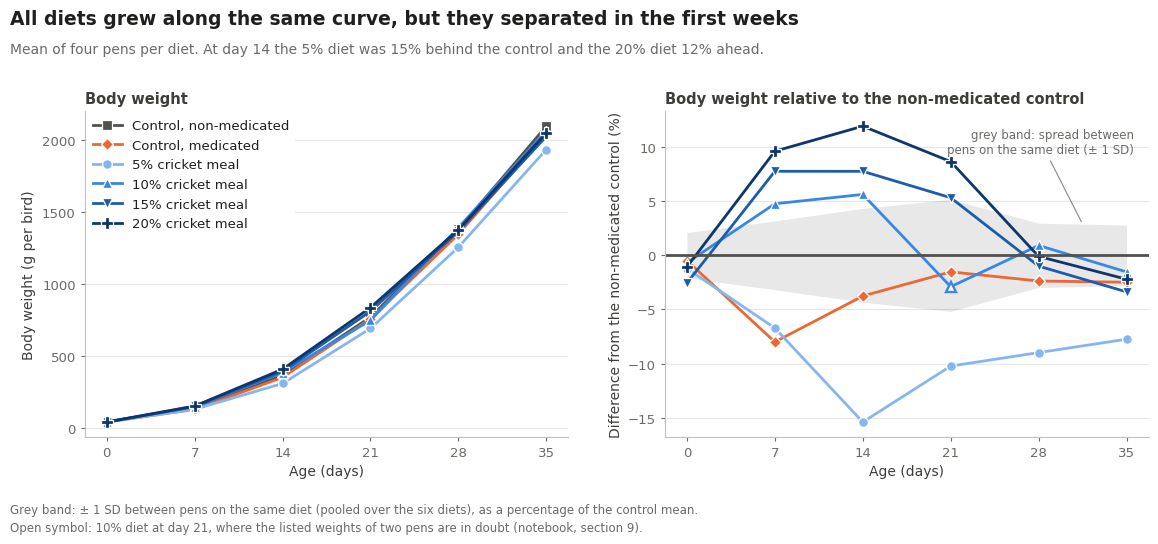

In [51]:
days = bw_mean.columns.to_numpy()
# Spread between pens on the same diet (section 11), as a percentage of the control mean
spread_band = 100 * sd_within_diets / bw_mean.loc["0% NM"]

fig, (ax_bw, ax_rel) = plt.subplots(1, 2, figsize=(11.5, 5.25))
fig.subplots_adjust(left=0.065, right=0.99, top=0.805, bottom=0.185, wspace=0.2)

ax_rel.fill_between(days, -spread_band, spread_band, color=diet_colors["0% NM"], alpha=0.13, linewidth=0, zorder=1)

for diet in diet_order:
    line_style = dict(color=diet_colors[diet], marker=diet_markers[diet], markersize=marker_sizes[diet],
                      markeredgecolor="white", markeredgewidth=0.9, linewidth=2)
    ax_bw.plot(days, bw_mean.loc[diet], label=diet_labels[diet], **line_style)
    # The curves lie almost on top of each other, so the second panel shows each diet against the control
    if diet != "0% NM":
        ax_rel.plot(days, relative_bw.loc[diet], **line_style)

# The day-21 mean of the 10% diet rests on two doubtful pen weights (section 9.1): open symbol
ax_rel.plot(21, relative_bw.loc["10% CM", 21], marker=diet_markers["10% CM"], markersize=marker_sizes["10% CM"],
            markerfacecolor="white", markeredgecolor=diet_colors["10% CM"], markeredgewidth=1.7, zorder=5)

ax_bw.set(xlabel="Age (days)", ylabel="Body weight (g per bird)", xticks=days)
ax_bw.set_title("Body weight", loc="left", fontsize=10.5, fontweight="bold", color="#3d3d3a")
ax_bw.legend(loc="upper left", fontsize=9.5, handlelength=2.2, borderaxespad=0.2, **legend_box)

ax_rel.axhline(0, color=diet_colors["0% NM"], linewidth=2, zorder=2)
ax_rel.set(xlabel="Age (days)", ylabel="Difference from the non-medicated control (%)", xticks=days)
ax_rel.set_title("Body weight relative to the non-medicated control", loc="left", fontsize=10.5, fontweight="bold", color="#3d3d3a")
ax_rel.annotate("grey band: spread between\npens on the same diet (± 1 SD)", xy=(31.5, np.interp(31.5, days, spread_band)), xytext=(35.6, 9.2),
                ha="right", va="bottom", fontsize=8.5, color=MUTED,
                arrowprops={"arrowstyle": "-", "color": "#898781", "linewidth": 0.8, "shrinkB": 2})

for ax in (ax_bw, ax_rel):
    ax.grid(axis="x", visible=False)
    ax.tick_params(length=3)

headline(fig, "All diets grew along the same curve, but they separated in the first weeks",
         "Mean of four pens per diet. At day 14 the 5% diet was 15% behind the control and the 20% diet 12% ahead.")
footnote(fig, "Grey band: ± 1 SD between pens on the same diet (pooled over the six diets), as a percentage of the control mean.\n"
              "Open symbol: 10% diet at day 21, where the listed weights of two pens are in doubt (notebook, section 9).")
fig.savefig(FIGURE_DIR / "figure_1_growth_curve.png")
plt.show()

On the usual scale (left) the six curves are hard to tell apart: all diets grew along the same curve to about 2 kg. The SDs are left out of this panel because they would be hidden behind the symbols. They are in the table of section 11.

The differences are in the right panel. The grey band shows how much pens on the same diet differ from each other (± 1 SD). A diet mean inside the band is no further from the control than pens of one diet are from each other. The 10, 15 and 20% CM diets were ahead of the control at days 7 and 14, in dose order. They were level with it at day 28 and slightly below it at day 35. The 5% CM diet fell behind in the first two weeks and only partly caught up. The medicated control was below the non-medicated one at every weighing. The open symbol marks the day-21 mean of the 10% diet, which rests on two doubtful pen weights (section 9.1).

### Figure 2. Feed intake over time

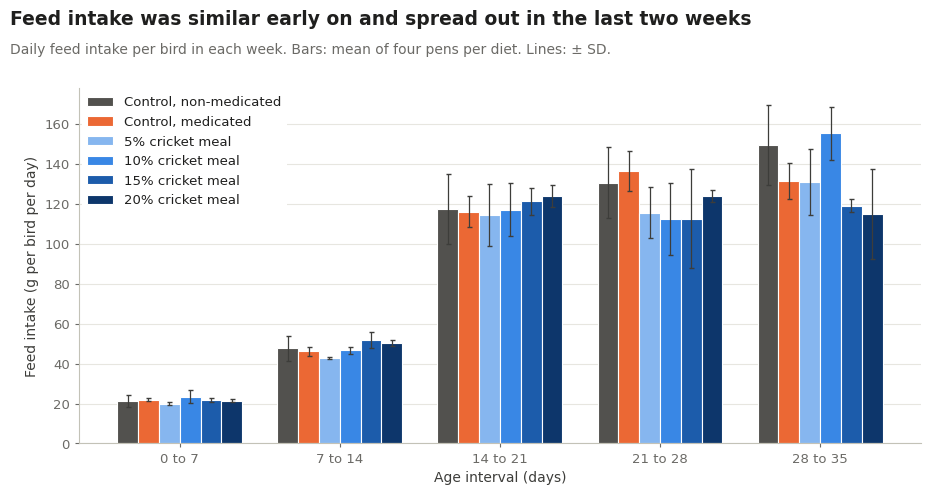

In [52]:
weeks = np.arange(1, 6)
bar_width = 0.13

fig, ax = plt.subplots(figsize=(9.2, 4.9))
fig.subplots_adjust(left=0.075, right=0.99, top=0.84, bottom=0.115)

for i, diet in enumerate(diet_order):
    # Six bars per week, centred on the week
    ax.bar(weeks + (i - 2.5) * bar_width, fi_by_week.loc[diet, "mean"], width=bar_width,
           yerr=fi_by_week.loc[diet, "std"], color=diet_colors[diet], edgecolor="white", linewidth=0.8,
           error_kw={"elinewidth": 0.9, "capsize": 1.8, "ecolor": "#3d3d3a"}, label=diet_labels[diet])

ax.set(xlabel="Age interval (days)", ylabel="Feed intake (g per bird per day)")
ax.set_xticks(weeks, ["0 to 7", "7 to 14", "14 to 21", "21 to 28", "28 to 35"])
ax.grid(axis="x", visible=False)
ax.tick_params(length=3)
ax.legend(loc="upper left", fontsize=9.5, borderaxespad=0.2, **legend_box)

headline(fig, "Feed intake was similar early on and spread out in the last two weeks",
         "Daily feed intake per bird in each week. Bars: mean of four pens per diet. Lines: ± SD.")
fig.savefig(FIGURE_DIR / "figure_2_feed_intake.png")
plt.show()

Intake was similar across diets in the first three weeks. The 5% CM pens had the lowest intake in weeks 1 and 2, which is when they fell behind in weight. In weeks 4 and 5 the diets spread out, but so do the pens within a diet (long error lines), and these are the weeks with the doubtful intake records (sections 8.3 and 9.1). The step between weeks 2 and 3 is the pattern discussed in section 12.

### Figure 3. Final body weight by diet

Figures 3 and 4 use the same layout. Each row is a diet and each dot is one pen, so the spread between pens stays visible. The thick tick is the diet mean and the shaded band is the mean ± SD. The dashed line marks the mean of the non-medicated control, and the columns on the right give each diet's mean and its difference from that control.

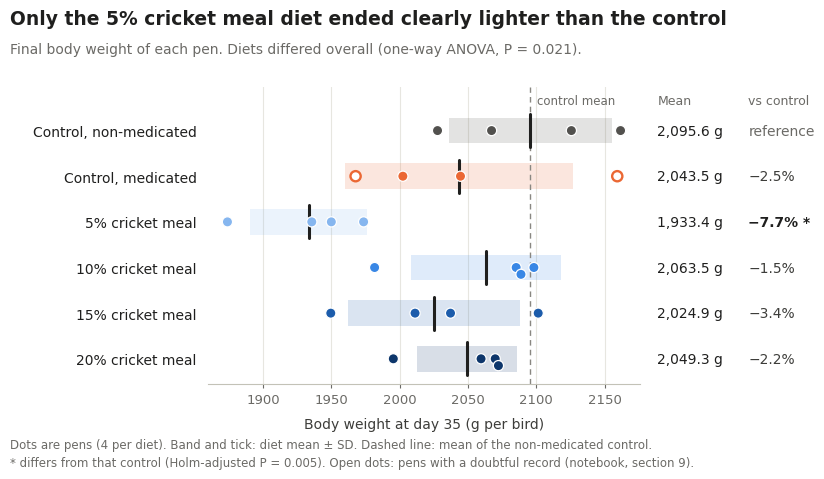

In [53]:
def spread(values, gap):
    """Small up and down shifts so that dots closer together than `gap` do not hide each other."""
    shifts, last, direction = [], None, 1
    for value in values:
        if last is not None and value - last < gap:
            shifts.append(0.15 * direction)
            direction = -direction
        else:
            shifts.append(0.0)
            direction = 1
        last = value
    return np.array(shifts)


def plot_pens_by_diet(column, xlabel, title, subtitle, fmt, comparisons=None, open_dots=None, note=""):
    """One row per diet: pen values as dots, the diet mean as a tick and mean ± SD as a band."""
    fig, ax = plt.subplots(figsize=(9.2, 4.6))
    fig.subplots_adjust(left=0.215, right=0.685, top=0.83, bottom=0.185)

    by_diet = pen_summary.groupby("diet", observed=True)[column]
    means, sds = by_diet.mean(), by_diet.std()
    control_mean = means["0% NM"]
    value_range = pen_summary[column].max() - pen_summary[column].min()

    for row, diet in enumerate(diet_order):
        pens = pen_summary[pen_summary["diet"] == diet].sort_values(column)
        color = diet_colors[diet]
        ax.barh(row, 2 * sds[diet], left=means[diet] - sds[diet], height=0.56, color=color, alpha=0.16, zorder=1)
        ax.plot([means[diet]] * 2, [row - 0.36, row + 0.36], color=INK, linewidth=2.2, solid_capstyle="round", zorder=3)
        # Pens with a doubtful record are drawn as open dots
        hollow = np.zeros(len(pens), dtype=bool) if open_dots is None else open_dots[pens.index].to_numpy()
        ax.scatter(pens[column], row + spread(pens[column].to_numpy(), 0.022 * value_range), s=54,
                   facecolors=np.where(hollow, "white", color), edgecolors=np.where(hollow, color, "white"),
                   linewidths=np.where(hollow, 1.7, 0.9), zorder=4)

    ax.axvline(control_mean, color="#898781", linewidth=1, linestyle=(0, (4, 3)), zorder=2)
    ax.annotate("control mean", (control_mean, -0.66), xytext=(5, 0), textcoords="offset points",
                fontsize=8.5, color=MUTED, va="center")

    ax.set_yticks(range(len(diet_order)))
    ax.set_yticklabels([diet_labels[diet] for diet in diet_order], color=INK, fontsize=10)
    ax.set_ylim(len(diet_order) - 0.45, -0.95)
    ax.tick_params(axis="y", length=0, pad=8)
    ax.tick_params(axis="x", length=3)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.set_xlabel(xlabel, labelpad=8)

    # Two columns of numbers to the right of the plot: the diet mean and its difference from the control
    beside = ax.get_yaxis_transform()
    ax.text(1.04, -0.66, "Mean", transform=beside, fontsize=9, color=MUTED, va="center")
    ax.text(1.25, -0.66, "vs control", transform=beside, fontsize=9, color=MUTED, va="center")
    for row, diet in enumerate(diet_order):
        ax.text(1.04, row, fmt(means[diet]), transform=beside, va="center", fontsize=10, color=INK)
        if diet == "0% NM":
            ax.text(1.25, row, "reference", transform=beside, va="center", fontsize=10, color=MUTED)
            continue
        starred = comparisons is not None and comparisons.loc[diet, "P (Holm)"] < 0.05
        label = f"{100 * (means[diet] / control_mean - 1):+.1f}%".replace("-", "\u2212") + (" *" if starred else "")
        ax.text(1.25, row, label, transform=beside, va="center", fontsize=10,
                color=INK if starred else "#3d3d3a", fontweight="bold" if starred else "normal")

    headline(fig, title, subtitle)
    footnote(fig, note)
    return fig, ax


anova_final_bw = anova_across_diets(pen_summary["final_bw_g"])

fig, ax = plot_pens_by_diet(
    "final_bw_g", "Body weight at day 35 (g per bird)",
    title="Only the 5% cricket meal diet ended clearly lighter than the control",
    subtitle=f"Final body weight of each pen. Diets differed overall (one-way ANOVA, P = {anova_final_bw['P']:.3f}).",
    fmt=lambda value: f"{value:,.1f} g",
    comparisons=final_bw_vs_control,
    open_dots=pen_summary["final_weight_in_doubt"],
    note="Dots are pens (4 per diet). Band and tick: diet mean ± SD. Dashed line: mean of the non-medicated control.\n"
         f"* differs from that control (Holm-adjusted P = {final_bw_vs_control.loc['5% CM', 'P (Holm)']:.3f}). "
         "Open dots: pens with a doubtful record (notebook, section 9).",
)
fig.savefig(FIGURE_DIR / "figure_3_final_body_weight.png")
plt.show()

All four 5% CM pens finished below 1975 g, while 18 of the other 20 pens finished above it. This is the only diet that differs from the control after adjustment (marked with a star). The other diets overlap with each other and with the two controls. The medicated control has the widest spread, and its lightest and heaviest pens are the two whose final weight is in doubt (open dots).

### Figure 4. Feed conversion ratio by diet

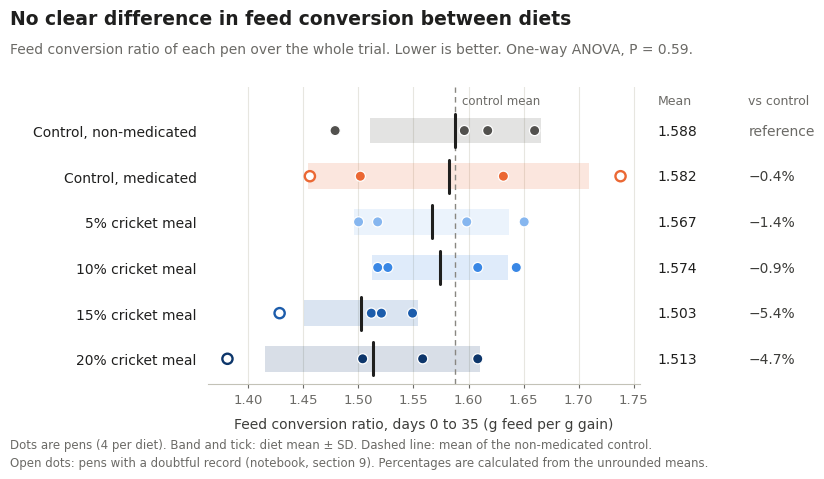

In [54]:
anova_fcr = anova_across_diets(pen_summary["fcr"])

fig, ax = plot_pens_by_diet(
    "fcr", "Feed conversion ratio, days 0 to 35 (g feed per g gain)",
    title="No clear difference in feed conversion between diets",
    subtitle=f"Feed conversion ratio of each pen over the whole trial. Lower is better. One-way ANOVA, P = {anova_fcr['P']:.2f}.",
    fmt=lambda value: f"{value:.3f}",
    open_dots=pen_summary["final_weight_in_doubt"] | pen_summary["weekly_intake_in_doubt"],
    note="Dots are pens (4 per diet). Band and tick: diet mean ± SD. Dashed line: mean of the non-medicated control.\n"
         "Open dots: pens with a doubtful record (notebook, section 9). Percentages are calculated from the unrounded means.",
)
fig.savefig(FIGURE_DIR / "figure_4_fcr.png")
plt.show()

FCR over the whole trial, where lower is better. The diets overlap almost completely. The 15 and 20% CM diets have the lowest means (5.4 and 4.7% below the control). But the two lowest points of the whole trial are open dots. They are pens 8 and 24, the two pens with an implausibly low recorded feed intake in one week (section 9.1). That apparent advantage should not be trusted. In the medicated control the highest and lowest values are again pens 18 and 20.

## 14. Main findings

**How did dietary cricket-meal inclusion influence broiler growth and feed efficiency?**

1. **All diets grew along the same curve to about 2 kg.** Diet means at day 35 ranged from 1933 g (5% CM) to 2096 g (non-medicated control).
2. **The 5% CM diet was the one that stood out.** Final body weight differed among diets (one-way ANOVA on pen values, P = 0.021). The 5% CM pens were 7.7% lighter than the non-medicated control (Holm-adjusted P = 0.005), and all four were among the six lightest pens of the trial. The 10, 15 and 20% CM diets ended 1.5 to 3.4% below that control, about the same as the medicated control (2.5% below). None of these four differed from the control.
3. **The diets separated early, not late.** At day 14 the 5% CM birds were 15% lighter than the non-medicated control and the 20% CM birds 12% heavier (adjusted P = 0.0004 and 0.004). The 10 and 15% CM birds were 6 and 8% heavier, which is not certain with four pens per diet (adjusted P = 0.17 and 0.06). By day 28 the three higher levels were within about 1% of the control. At day 35 the cricket-meal diets ranked 10%, 20%, 15% and 5% from heaviest to lightest, so final weight did not follow the inclusion level.
4. **In the 5% CM diet, lower weight went with lower intake.** Feed intake over 35 days ranged from 2968.4 g per bird (5% CM) to 3265.5 g (non-medicated control), with weak evidence of a diet effect (P = 0.13). The 5% CM pens ate 9.1% less and gained 7.9% less than the control. The 15 and 20% CM pens also ate less (8.5 and 6.9%), but gained only 3.4 and 2.2% less.
5. **No clear difference in feed efficiency.** FCR over 35 days was 1.50 to 1.59 across diets (P = 0.59). With four pens per diet this does not prove that the diets convert feed equally well.
6. **The data needed care before any of this could be said.** Pen numbers had to be restored in 126 of 144 rows. Ten pens appear to have started with 27 birds, not the 26 of the description. The supplied gain column disagrees with the weight column in 14 of 120 pen-weeks, which traces back to different bird numbers in six pens. For two pens of the medicated control this leaves about 100 g of doubt in the final weight. The conclusions above are the same with either version of the numbers.

In short: in this trial, cricket meal at 10 to 20% of the diet gave growth and feed efficiency close to those of the control diets. The 5% level gave lower intake and lower weight, which the data in this workbook cannot explain.

## 15. Limitations

- **Four pens per diet.** The SDs and the ANOVA rest on four values per diet. Only large differences can be detected, and "no evidence of a difference" is not evidence that there is none.
- **Per-bird means only.** The workbook has no pen weights, bird counts or feed weigh-backs. Feed intake per bird is used as supplied. It could not be recalculated or corrected for mortality.
- **Bird numbers.** In six pens the weights and the gains were calculated with different bird numbers (section 9.1). For pens 18 and 20 this leaves about 100 g of doubt in the final weight. I kept the recorded weights, although the mortality column points the other way for pen 18. Only the original records could settle it.
- **Weekly feed records.** Intake per bird fell from one week to the next in 21 of 96 steps, week-3 FCR is high in every diet and two weekly FCR values are below 1. Only 35-day intake and FCR are interpreted, and the two lowest 35-day FCR values come from the two pens with a doubtful weekly intake.
- **Shrinking pens.** Three birds per pen were taken out on days 13 and 20, so the means at later ages rest on fewer birds than those at the start.
- **Scope.** One trial, one strain, 35 days. Diet composition is not in the workbook, so this notebook does not try to explain why the 5% CM diet performed differently.
- **Not the published analysis.** The one-way ANOVA and the comparisons with the control are simple checks on pen values and may differ from the model used in the article.

## 16. Reproducibility information

The notebook runs from top to bottom with no manual steps other than providing the workbook. No random numbers are used, so every run gives the same tables and figures. The SHA-256 printed in section 4 is a fingerprint of the file. The same value means that exactly the same workbook was analysed.

In [55]:
print("Python    ", platform.python_version())
for module in (pd, np, matplotlib, scipy, openpyxl):
    print(f"{module.__name__:10s}", module.__version__)

Python     3.12.3
pandas     2.2.2
numpy      2.0.2
matplotlib 3.10.0
scipy      1.16.3
openpyxl   3.1.5
